In [7]:
from pathlib import Path
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path(".")
GT_DIR = BASE_DIR / "groundtruth"
PRED_CSV = BASE_DIR / "P2E_S1_C3.csv"

xml_files = sorted(GT_DIR.glob("P2E_S1_C3*.xml"))
gt_records = []

for xml_path in xml_files:
    tree = ET.parse(xml_path)
    root = tree.getroot()
    for frame_elem in root.findall(".//frame"):
        num_str = frame_elem.attrib.get("number", "")
        if not num_str.isdigit():
            continue
        frame_num = int(num_str)
        for ps in frame_elem.findall(".//person"):
            pid = str(ps.attrib.get("id", "")).strip()
            if pid:
                gt_records.append({
                    "frame_num": frame_num,
                    "gt_person_id": pid.zfill(4) if pid.isdigit() else pid,
                })

df_gt = pd.DataFrame(gt_records)
df_pred = pd.read_csv(PRED_CSV)
df_pred["frame_num"] = pd.to_numeric(df_pred["frame"], errors="coerce")
df_pred = df_pred.dropna(subset=["frame_num"]).copy()
df_pred["frame_num"] = df_pred["frame_num"].astype(int)
df_pred["pred_id"] = df_pred["best_id"].astype(str).str.strip().apply(
    lambda x: x.zfill(4) if x.isdigit() else x
)

if len(df_gt) > 0:
    gt_pairs = set(zip(df_gt["frame_num"], df_gt["gt_person_id"]))
    df_pred["is_match"] = [
        1 if (f, p) in gt_pairs else 0
        for f, p in zip(df_pred["frame_num"], df_pred["pred_id"])
    ]
    metric_label = "GT ID Match Rate"
else:
    df_pred["is_match"] = (
        df_pred["matches_label"].astype(str).str.strip().str.lower().map({"true": 1, "1": 1, "false": 0, "0": 0})
    )
    metric_label = "Matches Label Rate"

valid = df_pred["is_match"].dropna()
n = int(len(valid))
rate = float(valid.mean()) if n > 0 else 0.0
se = np.sqrt(rate * (1.0 - rate) / max(n, 1))
ci_low = max(0.0, rate - 1.96 * se)
ci_high = min(1.0, rate + 1.96 * se)

summary = pd.DataFrame([{
    "Sequence": "P2E_S1_C3",
    "Metric": metric_label,
    "Samples (N)": n,
    "Rate": round(rate, 4),
    "95% CI Lower": round(ci_low, 4),
    "95% CI Upper": round(ci_high, 4),
}])

summary

,Sequence,Metric,Samples (N),Rate,95% CI Lower,95% CI Upper
0,P2E_S1_C3,GT ID Match Rate,2247,0.7583,0.7406,0.776


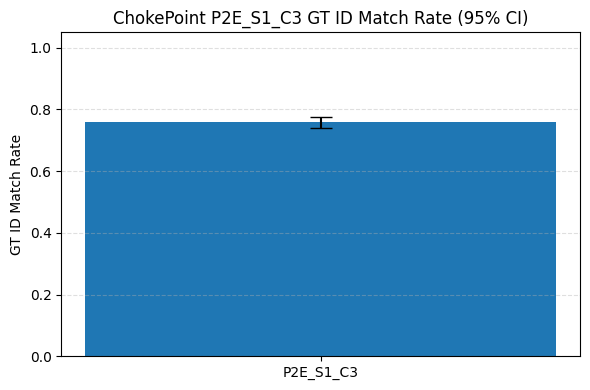

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    ["P2E_S1_C3"],
    [rate],
    yerr=[[rate - ci_low], [ci_high - rate]],
    capsize=8,
)
ax.set_ylim(0, 1.05)
ax.set_ylabel(metric_label)
ax.set_title(f"ChokePoint P2E_S1_C3 {metric_label} (95% CI)")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()